---
title: "Practice Activity 8-2: Introduction to Machine Learning and Linear Regression Models"
author: "Shiqi Wu"
format:
  html:
    embed-resources: true
    code-overflow: wrap
execute:
  enabled: false
---

# Intro to Machine Learning; Linear Regression Models

In [2]:
import pandas as pd

import numpy as np

## Music Challenge

Which popular songs from the past will be recognized by future generations, and which will fade into obscurity? The website [The Pudding](https://pudding.cool/) conducts the [Music Challenge](https://pudding.cool/2020/04/music-challenge/) where they ask thousands of people whether they recognize hit songs from the past. We'll look at some of the [data](https://github.com/the-pudding/song-decay-clean/tree/master/src/assets/data) related to the article ["Defining the 90s Music Canon"](https://pudding.cool/2020/07/song-decay/).

The data set at https://raw.githubusercontent.com/the-pudding/song-decay-clean/refs/heads/master/src/assets/data/lollipop_chart_data_july_13.csv contains 344 songs released in the 1990s. For each song, the proportion of survey respondents who recognized the song is recorded, for both Millennial respondents and Gen Z respondents. Our goal will be to use linear regression to **predict the Gen Z recognition**.

We will try several different linear regression models. Save each of your models with a different name because you will compare them at the end.



0. Read in the data and describe the Gen Z recognition variable.

In [3]:
df_music = pd.read_csv("https://raw.githubusercontent.com/the-pudding/song-decay-clean/refs/heads/master/src/assets/data/lollipop_chart_data_july_13.csv")

print("Data shape:", df_music.shape)
display(df_music.head())

df_music["mean_gen_z_recognition"].describe()

Data shape: (344, 3)


,artist_song,mean_millennial_recognition,mean_gen_z_recognition
0,2 Pac|||California Love,0.517602,0.268378
1,2Pac|||How Do U Want It,0.209632,0.062439
2,702|||Where My Girls At?,0.553481,0.244176
3,Ace Of Base|||All That She Wants,0.830967,0.540097
4,Ace Of Base|||Don't Turn Around,0.623149,0.372787


count    344.000000
mean       0.235506
std        0.210541
min        0.019483
25%        0.095589
50%        0.155398
75%        0.303051
max        0.963497
Name: mean_gen_z_recognition, dtype: float64

Answer: Gen Z recognition is a quantitative variable measuring the proportion of Gen Z respondents who recognized each song. For the 344 songs, the mean is about 0.236 and the median is about 0.155. Recognition ranges from about 0.019 to 0.963, with no missing values. The mean is higher than the median, suggesting a right-skewed distribution.

1. Use scikit-learn to fit a linear regression model for predicting Gen Z recognition from Millennial recognition.

In [4]:
from sklearn.linear_model import LinearRegression

X_music = df_music[["mean_millennial_recognition"]]
y_music = df_music["mean_gen_z_recognition"]

model_linear = LinearRegression()
model_linear.fit(X_music, y_music)

print("Intercept:", model_linear.intercept_)
print("Coefficient:", model_linear.coef_[0])

Intercept: -0.04814972198183062
Coefficient: 0.7067311793153613


2. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model from the previous part.

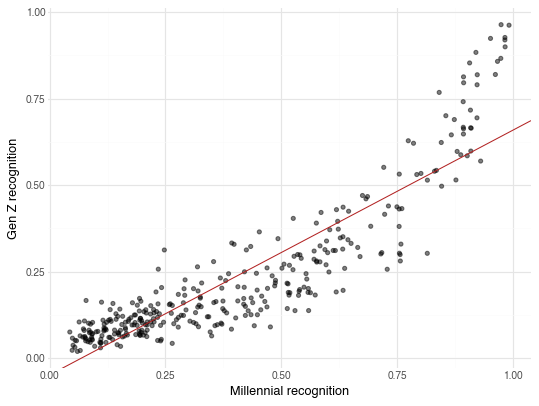

In [5]:
from plotnine import ggplot, aes, geom_point, geom_abline, labs, theme_minimal

(
    ggplot(df_music, aes(x="mean_millennial_recognition", y="mean_gen_z_recognition"))
    + geom_point(alpha=0.5)
    + geom_abline(
        intercept=model_linear.intercept_,
        slope=model_linear.coef_[0],
        color="firebrick"
    )
    + labs(x="Millennial recognition", y="Gen Z recognition")
    + theme_minimal()
)

3. Explain why you might want to consider taking a log of Gen Z recognition. Then use scikit-learn to fit a linear regression model for predicting log of Gen Z recognition from Millennial recognition.

In [6]:
df_music["log_gen_z_recognition"] = np.log(df_music["mean_gen_z_recognition"])

model_log = LinearRegression()
model_log.fit(X_music, df_music["log_gen_z_recognition"])

print("Intercept:", model_log.intercept_)
print("Coefficient:", model_log.coef_[0])

Intercept: -2.9082912239452847
Coefficient: 2.7991680362225226


Answer: The scatterplot shows an upward-curving relationship, and the spread of Gen Z recognition appears larger at higher Millennial recognition levels. Taking the log of Gen Z recognition may make the relationship more linear and reduce the differences in spread. All Gen Z recognition values are positive, so the log transformation is defined.

4. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model from the previous part.

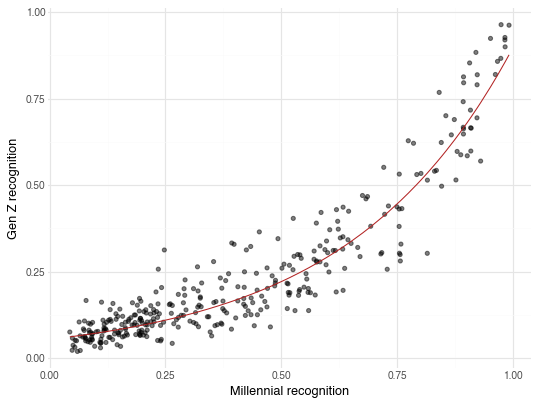

In [7]:
from plotnine import geom_line

df_music["pred_from_log"] = np.exp(model_log.predict(X_music))

(
    ggplot(df_music, aes(x="mean_millennial_recognition", y="mean_gen_z_recognition"))
    + geom_point(alpha=0.5)
    + geom_line(aes(y="pred_from_log"), color="firebrick")
    + labs(x="Millennial recognition", y="Gen Z recognition")
    + theme_minimal()
)

5. Now we'll try a polynomial model for predicting Gen Z recognition from Millennial recognition. Use scikit-learn to fit a model with two features: Millennial recognition and its square.

In [9]:
df_music["millennial_squared"] = df_music["mean_millennial_recognition"] ** 2

X_square = df_music[["mean_millennial_recognition", "millennial_squared"]]

square_model = LinearRegression()
square_model.fit(X_square, y_music)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [10]:
square_model.coef_, square_model.intercept_

(array([-0.27263527,  1.02072241]), np.float64(0.10851294576257645))

6. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model.

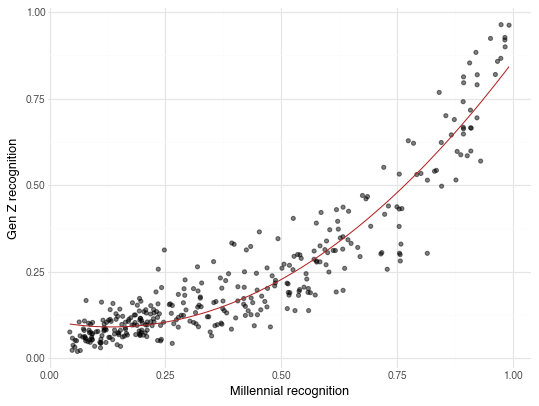

In [11]:
df_music["pred_from_square"] = square_model.predict(X_square)

(
    ggplot(df_music, aes(x="mean_millennial_recognition", y="mean_gen_z_recognition"))
    + geom_point(alpha=0.5)
    + geom_line(aes(y="pred_from_square"), color="firebrick")
    + labs(x="Millennial recognition", y="Gen Z recognition")
    + theme_minimal()
)

7. Choose one of your favorite songs that is in the data set. Use each model to predict the Gen Z recognition for the song. Which model gives the best prediction?

In [12]:
song = df_music.loc[df_music["artist_song"] == "Britney Spears|||..Baby One More Time"]

predictions = pd.DataFrame({
    "Model": ["Linear", "Log", "Quadratic"],
    "Predicted recognition": [
        model_linear.predict(song[["mean_millennial_recognition"]])[0],
        np.exp(model_log.predict(song[["mean_millennial_recognition"]]))[0],
        square_model.predict(song[["mean_millennial_recognition", "millennial_squared"]])[0]
    ]
})

predictions["Actual recognition"] = song["mean_gen_z_recognition"].iloc[0]
predictions["Absolute error"] = (predictions["Predicted recognition"] - predictions["Actual recognition"]).abs()

predictions.round(4)

,Model,Predicted recognition,Actual recognition,Absolute error
0,Linear,0.6528,0.962,0.3091
1,Log,0.8764,0.962,0.0856
2,Quadratic,0.8423,0.962,0.1197


Answer: I chose “..Baby One More Time” by Britney Spears. Its actual Gen Z recognition is about 0.962. The linear model predicts 0.6528, the log model predicts 0.8764, and the quadratic model predicts 0.8423. The log model gives the best prediction for this song because its absolute error, 0.0856, is the smallest. However, this single song does not show which model predicts best overall.

8. The song "Smells Like Teen Spirit" by Nirvana is inexplicably not included in the data set. Suppose the Millenial recognition of this song is 0.7. Use each model to predict the Gen Z recognition for this song. Which model gives the best prediction?

In [13]:
new_song = pd.DataFrame({"mean_millennial_recognition": [0.7]})
new_song["millennial_squared"] = new_song["mean_millennial_recognition"] ** 2

nirvana_predictions = pd.DataFrame({
    "Model": ["Linear", "Log", "Quadratic"],
    "Predicted recognition": [
        model_linear.predict(new_song[["mean_millennial_recognition"]])[0],
        np.exp(model_log.predict(new_song[["mean_millennial_recognition"]]))[0],
        square_model.predict(new_song[["mean_millennial_recognition", "millennial_squared"]])[0]
    ]
})

nirvana_predictions.round(4)

,Model,Predicted recognition
0,Linear,0.4466
1,Log,0.3872
2,Quadratic,0.4178


Answer: For “Smells Like Teen Spirit,” with Millennial recognition of 0.7, the linear model predicts Gen Z recognition of 0.4466, the log model predicts 0.3872, and the quadratic model predicts 0.4178. We cannot determine which prediction is best because the actual Gen Z recognition is not provided. We would need the actual value to compare prediction errors for this song.

## Categorical Predictors (FEV data)

Do non-smokers have better lungs than smokers? One measure of lung function is forced expiratory volume (FEV), the amount of air (in liters) an individual can exhale in the first second of forceful breath.  Larger values of FEV are indicative of better functioning lungs. In a study, FEV was measured for a group of 654 subjects, along with whether or not they smoked and other variables.

In [14]:
df_fev = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/FEV.csv")

df_fev

,ID,Smoking status,FEV,Height,Age (months)
0,201,non-smoker,2.884,69.0,132
1,202,non-smoker,2.328,64.0,120
2,301,non-smoker,1.708,57.0,108
3,341,non-smoker,3.381,63.0,172
4,351,non-smoker,2.170,58.0,130
...,...,...,...,...,...
649,83841,non-smoker,2.115,50.0,58
650,83901,non-smoker,2.328,60.0,98
651,83951,smoker,3.069,65.0,130
652,83952,non-smoker,1.495,57.0,85


1\. First fit a regression model with a single predictor: Smoking status. Since this variable is categorical you need to "dummify" it before fitting the model.

In [15]:
X_smoking = pd.get_dummies(df_fev[["Smoking status"]], drop_first=True, dtype=int)
y_fev = df_fev["FEV"]

model_smoking = LinearRegression()
model_smoking.fit(X_smoking, y_fev)

print("Intercept:", model_smoking.intercept_)
print("Smoking coefficient:", model_smoking.coef_[0])

Intercept: 2.5661426146010187
Smoking coefficient: 0.7107189238605222


2\. What are the predictions from this model? How could we have known that those would be the predictions?

In [16]:
smoking_groups = pd.DataFrame({"Smoking status_smoker": [0, 1]})

fev_predictions = pd.DataFrame({
    "Smoking status": ["non-smoker", "smoker"],
    "Predicted FEV": model_smoking.predict(smoking_groups)
})

display(fev_predictions.round(4))

df_fev.groupby("Smoking status")["FEV"].mean().round(4)

,Smoking status,Predicted FEV
0,non-smoker,2.5661
1,smoker,3.2769


Smoking status
non-smoker    2.5661
smoker        3.2769
Name: FEV, dtype: float64

Answer: The model predicts an FEV of about 2.5661 liters for non-smokers and 3.2769 liters for smokers. These are exactly the sample mean FEV values for the two groups. We could have obtained these predictions by calculating the group means, because a linear regression with an intercept and only one categorical predictor predicts the mean of each category.

3\. Look at the results for the previous parts. What do you notice? Is this what you expected? Remember: larger FEV means better lungs - who tends to have larger FEV, smokers or non-smokers?

Answer: Smokers have a higher average FEV in this sample: about 3.2769 liters compared with 2.5661 liters for non-smokers. This is surprising because we might expect non-smokers to have higher FEV. However, this model only considers smoking status and does not account for differences in age or height. The result does not show that smoking improves lung function.

4\. Suggest some explanations for why smokers tend to have *higher* FEV than non-smokers?

Answer: Smokers in this sample may be older or taller than non-smokers. Older and taller children generally have larger lung volumes and higher FEV. Therefore, differences in age or height could explain why smokers have a higher average FEV. These variables may confound the relationship between smoking status and FEV, so the difference should not be interpreted as a benefit of smoking.

5\. Fit a linear regression model with two predictors: smoking status and Age (and no interaction).

In [17]:
X_smoking_age = X_smoking.copy()
X_smoking_age["Age (months)"] = df_fev["Age (months)"]

model_smoking_age = LinearRegression()
model_smoking_age.fit(X_smoking_age, y_fev)

print("Intercept:", model_smoking_age.intercept_)
print(pd.Series(model_smoking_age.coef_, index=X_smoking_age.columns))

Intercept: 0.3681467500269182
Smoking status_smoker   -0.217178
Age (months)             0.019212
dtype: float64


6\. Make a scatterplot of FEV versus Age, colored by smoking status, and overlay a graph of the fitted model.

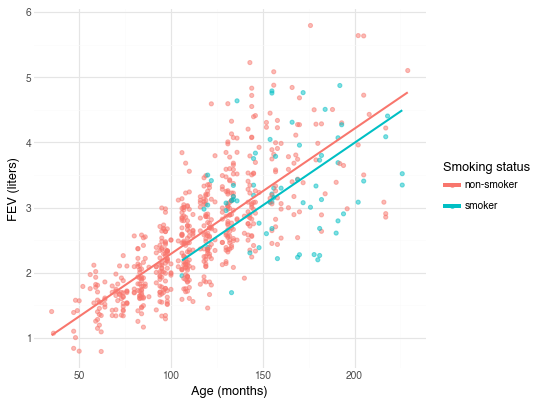

In [18]:
df_fev["pred_smoking_age"] = model_smoking_age.predict(X_smoking_age)

(
    ggplot(df_fev, aes(x="Age (months)", y="FEV", color="Smoking status"))
    + geom_point(alpha=0.5)
    + geom_line(aes(y="pred_smoking_age"), size=1)
    + labs(x="Age (months)", y="FEV (liters)", color="Smoking status")
    + theme_minimal()
)

7\. Fit a linear regression model with predictors smoking status, Age, and their interaction.

In [19]:
X_interaction = X_smoking_age.copy()
X_interaction["Smoking_x_age"] = X_interaction["Smoking status_smoker"] * X_interaction["Age (months)"]

model_interaction = LinearRegression()
model_interaction.fit(X_interaction, y_fev)

print("Intercept:", model_interaction.intercept_)
print(pd.Series(model_interaction.coef_, index=X_interaction.columns))

Intercept: 0.2594620232712441
Smoking status_smoker    1.870057
Age (months)             0.020162
Smoking_x_age           -0.013110
dtype: float64


8\. Make a scatterplot of FEV versus Age, colored by smoking status, and overlay a graph of the fitted model.

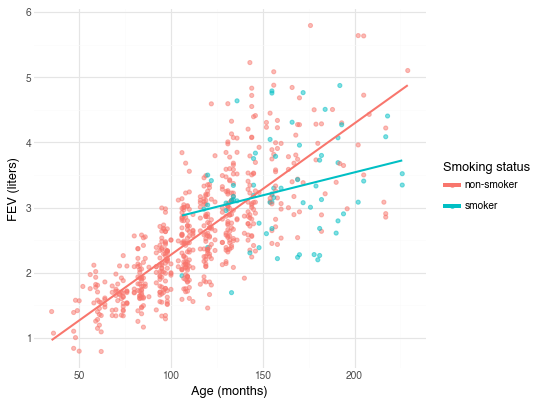

In [20]:
df_fev["pred_interaction"] = model_interaction.predict(X_interaction)

(
    ggplot(df_fev, aes(x="Age (months)", y="FEV", color="Smoking status"))
    + geom_point(alpha=0.5)
    + geom_line(aes(y="pred_interaction"), size=1)
    + labs(x="Age (months)", y="FEV (liters)", color="Smoking status")
    + theme_minimal()
)

9\. Compare the models. Which do you think is "best"? Why? How could you investigate?

Answer: The smoking-only model ignores age and predicts the same FEV for everyone in each smoking group. Adding age captures the relationship between age and FEV but assumes parallel lines. The interaction model allows different slopes for smokers and non-smokers. I would tentatively choose the interaction model because the plot suggests different age trends between the groups. However, better fit to the training data does not guarantee better predictions. I would compare all three models using the same cross-validation splits and their average RMSE. If their prediction errors are similar, I would prefer the simpler model.